In [2]:
import sklearn.datasets as ds
import numpy as np
import pandas as pa
import matplotlib.pyplot as plt
import statsmodels
from statsmodels.regression.linear_model import OLS

# Partie 1 - Régression linéaire

Dans cet exercice, nous allons travailler avec un dataset contenant des données socio-économiques et sur la criminalité de 1994 quartiers aux États-Unis dans les années 90.

Le dataset complet est décrit sur la page : https://archive.ics.uci.edu/dataset/183/communities+and+crime

L'objectif est de prédire le nombre de crimes violents pour 100 000 habitants (`ViolentCrimesPerPop`) en fonction des autres variables.

1. Commencez par charger les données depuis le fichier CSV `communities.csv`, et les explorer. Combien ce dataset compte-t-il d'observations et de facteurs ? Contient-il des données manquantes ?

In [21]:
data = pa.read_csv('communities.csv')
data.head()
# print(data.size) Il y a 191424 observations
#Il y a 96 colonnes donc, 96 facteurs

191424


2. Y a-t-il un lien entre la valeur cible <code>ViolentCrimesPerPro</code> et les différents facteurs ?

In [13]:
data.corr()
#On remarque que la corrélation entre ViolentCrimesPerPro et le reste des variables est peu significatif 

,population,householdsize,agePct12t21,agePct12t29,agePct16t24,agePct65up,numbUrban,pctUrban,medIncome,pctWWage,...,PctForeignBorn,PctBornSameState,PctSameHouse85,PctSameCity85,PctSameState85,LandArea,PopDens,PctUsePubTrans,LemasPctOfficDrugUn,ViolentCrimesPerPop
population,1.000000,-0.046148,0.006368,0.130344,0.075596,-0.102006,0.993112,0.239446,-0.101615,0.004512,...,0.172731,-0.125133,-0.123691,0.001610,-0.089638,0.713652,0.231897,0.270356,0.466352,0.367157
householdsize,-0.046148,1.000000,0.520461,0.367338,0.295225,-0.612666,-0.047581,-0.015739,0.209431,0.440269,...,0.311107,-0.049253,-0.057842,-0.103109,-0.003277,-0.015078,-0.004072,-0.051506,-0.094368,-0.034923
agePct12t21,0.006368,0.520461,1.000000,0.822424,0.894547,-0.410958,-0.021367,-0.239994,-0.296723,0.119776,...,-0.068537,0.080281,-0.357145,-0.361225,-0.150555,0.025736,-0.095749,-0.173279,0.001301,0.060477
agePct12t29,0.130344,0.367338,0.822424,1.000000,0.933720,-0.520637,0.112614,-0.089884,-0.342740,0.259699,...,0.077664,-0.047540,-0.559075,-0.505993,-0.317647,0.062476,0.119725,-0.023507,0.117290,0.153357
agePct16t24,0.075596,0.295225,0.894547,0.933720,1.000000,-0.323092,0.054579,-0.138893,-0.326803,0.103368,...,0.005594,-0.013802,-0.462897,-0.479077,-0.274540,0.031632,0.045979,-0.040419,0.083180,0.099347
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
LandArea,0.713652,-0.015078,0.025736,0.062476,0.031632,-0.124245,0.693445,0.081044,-0.047379,0.061147,...,-0.048845,-0.069273,-0.116901,-0.062989,-0.104403,1.000000,-0.170856,0.007699,0.299632,0.196800
PopDens,0.231897,-0.004072,-0.095749,0.119725,0.045979,0.015434,0.258147,0.331113,-0.023661,-0.034333,...,0.614772,-0.221341,0.020701,0.118082,-0.012166,-0.170856,1.000000,0.587804,0.228084,0.281390
PctUsePubTrans,0.270356,-0.051506,-0.173279,-0.023507,-0.040419,0.006786,0.298196,0.343561,0.250454,0.084611,...,0.401711,-0.175459,0.192367,0.081260,-0.042424,0.007699,0.587804,1.000000,0.206644,0.153829
LemasPctOfficDrugUn,0.466352,-0.094368,0.001301,0.117290,0.083180,-0.010168,0.478179,0.258955,-0.126211,-0.064602,...,0.170946,-0.134230,-0.090249,0.008227,-0.107289,0.299632,0.228084,0.206644,1.000000,0.348627


3. La valeur cible étant `ViolentCrimesPerPop`, créez un ensemble d'entraînement (80%) et de test (20%).

In [108]:
from sklearn.model_selection import train_test_split

X = data.drop(['ViolentCrimesPerPop'], axis =1)
y = data['ViolentCrimesPerPop']
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2)

4. En utilisant `OLS`, faites la régression multiple de la valeur cible `ViolentCrimesPerPop` en fonction des autres facteurs sur l'ensemble d'entraînement. 
Analysez le rapport obtenus.

In [110]:
model = OLS(y_train,X_train)
results = model.fit()
print(results.summary())


                                 OLS Regression Results                                 
Dep. Variable:     ViolentCrimesPerPop   R-squared (uncentered):                   0.844
Model:                             OLS   Adj. R-squared (uncentered):              0.835
Method:                  Least Squares   F-statistic:                              85.71
Date:                 Tue, 09 Dec 2025   Prob (F-statistic):                        0.00
Time:                         17:02:49   Log-Likelihood:                          976.31
No. Observations:                 1595   AIC:                                     -1763.
Df Residuals:                     1500   BIC:                                     -1252.
Df Model:                           95                                                  
Covariance Type:             nonrobust                                                  
                            coef    std err          t      P>|t|      [0.025      0.975]
--------------------

5. Utilisez la méthode `predict` de ce modèle pour prédire le nombre de crimes violents sur l'ensemble de test. Calculez l'erreur moyenne des différences au carré entre la prédiction et la vérité terrain. Justifiez pourquoi ce critère vous parait pertinent.

In [112]:
pred = results.predict(X_train)
print(pred)




1539    0.428925
674     0.484871
39      0.124791
705     0.150409
432    -0.001348
          ...   
1169    0.448092
257     0.086883
647     0.019962
1563    0.848554
773     0.146122
Length: 1595, dtype: float64


6. Quelle serait votre stratégie basée sur `OLS` pour diminuer le nombre de variables ? Détaillez en français (pas besoin de l'implémenter) ce que vous feriez précisément.

Pour diminuer le nombre de variables, nous devrons parcourir la colonne P>|t| fourni par notre régression multiple OLS et retirer les variables qui ont un P>|t| supérieur à 0.005 car ce sont des variables peu significative.

7. En utilisant `sklearn`, appliquez une ACP au jeu de données d'entraînement pour réduire sa dimensionnalité.

In [56]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

acp = PCA()
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X)
coord = acp.fit_transform(X_train_scaled)

8. Affichez l'éboulis des valeurs propres. 

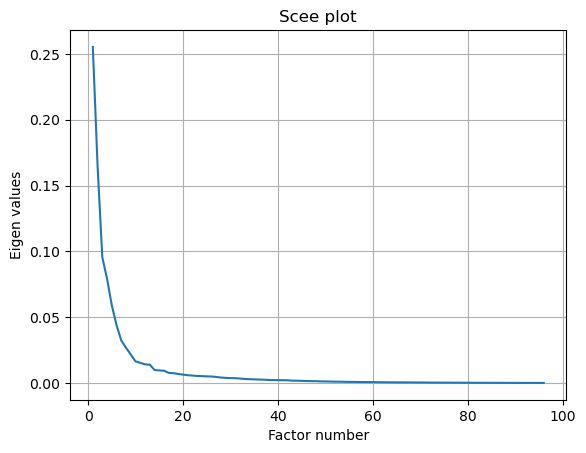

In [57]:
import numpy as np
import matplotlib.pyplot as plt

plt.grid()
plt.plot(np.arange(1,acp.n_components_+1),acp.explained_variance_ratio_)
plt.title("Scee plot")
plt.ylabel("Eigen values")
plt.xlabel("Factor number")
plt.show()

9. Combien d'axes faut-il retenir pour garder au moins 75% de la variance ?

In [58]:
p = 1
total_variance = 0
while total_variance < .75 :
    acp = PCA(n_components=p)
    coord = acp.fit_transform(X_train_scaled)
    total_variance = acp.explained_variance_ratio_.sum()
    p += 1
print('p = ', p)
print('total explained variance ratio: ', total_variance)

#On remarque un coude vers environ 10, mais d'après les calculs, 
#il faut au moins retenir 9 axes pour avoir au moins ~+75% de la variance

p =  9
total explained variance ratio:  0.7566068136535364


10. Ajustez un modèle de régression linéaire multiple aux données projetées sur ces axes. Comparez-le au modèle obtenu à la question 5.

In [113]:
pca = PCA(n_components=9)
X_train_proj = pca.fit_transform(X_train_scaled)


#olsmod = OLS(y_train, X_train_proj)
#olsres = olsmod.fit()
#print(olsres.summary())

#ypred = olsres.predict(X_train_proj)
#print(ypred)
#Ne compile pas

ValueError: endog and exog matrices are different sizes

11. Utilisez ce modèle pour prédire le nombre de crimes violents sur l'ensemble de test, et calculez l'erreur moyenne des différences au carré entre la prédiction et la vérité terrain. Comparez-la à l'erreur obtenue à la question 6.

12. Quel est le problème avec l'utilisation de l'ACP dans ce cas précis ?

# Partie 2 - Classification

Dans cet exercice vous utiliserez la bibliothèque `sklearn`. **On ne vous demande pas de recoder d'algorithme** de classification, de réduction en dimension ou de métrique d'évaluation d'un classifieur.

1. Chargez les données du fichier `data.csv` sous la forme d'un `DataFrame` `pandas`.

In [96]:
dt = pa.read_csv('data.csv')
dt.head()

,F1,F2,F3,F4,F5,F6,Classes
0,1.933100,0.671758,-0.291625,-0.271047,0.120160,-2.165320,1
1,-0.618482,-1.607866,0.906186,-0.917954,-0.588759,1.399676,0
2,-0.888283,-0.842878,1.395760,-0.299672,1.111914,0.815508,1
3,-1.888945,-1.553525,0.653320,-0.058589,-2.205408,2.117686,2
4,-0.604981,0.693135,-0.089177,1.273958,-1.801311,-0.861907,0


2. Définissez les variables `X` et `y` contenant respectivement les caractéristiques et les classes des exemples.

In [97]:
X = dt[['F1', 'F2', 'F3', 'F4','F5','F6']]
y = dt.Classes

3. Combien y a-t-il d'observations dans ce jeu de données ? Combien y a-t-il de classes ? Quelle est la dimension des observations ? Les classes sont-elles équilibrées ?

In [98]:
print(dt.Classes.unique())
print('nb classes uniques', len(dt.Classes.unique()))
print('nb classe 0 : ', len(dt[dt.Classes==0]))
print('nb classe 1 : ', len(dt[dt.Classes==1]))
print('nb classe 2 : ', len(dt[dt.Classes==2]))

#Il y a 3 classes, pour un total de 300 observations. Chacune des classes possèdent envrion 100 observation chacune
#les classes sont donc équilibrées

[1 0 2]
nb classes uniques 3
nb classe 0 :  94
nb classe 1 :  104
nb classe 2 :  102


4. À partir de ces données, créez l'ensemble d’entraînement (70% du total) et l'ensemble de test.

In [99]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.3)

5. Discuter du résultat d'un classifieur Bayésien MAP sur les données précédentes en commentant la matrice de confusion. L'_accuracy_ est-elle une mesure pertinente de la qualité de ce classifieur ?

Vous pouvez visualiser la matrice de confusion `cm` calculée avec la fonction `confusion_matrix` de `sklearn` en utilisant le code suivant :

In [100]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix

nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred = nb.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

#Comme les classes sont équilibrées l'accuracy et une variable qui a du sens car toutes les données sont proportionnelles
#Il n'y a pas de classes avec 1000 individus et 980 predict correct qui pourraient réduire la significativité de l'accuracy


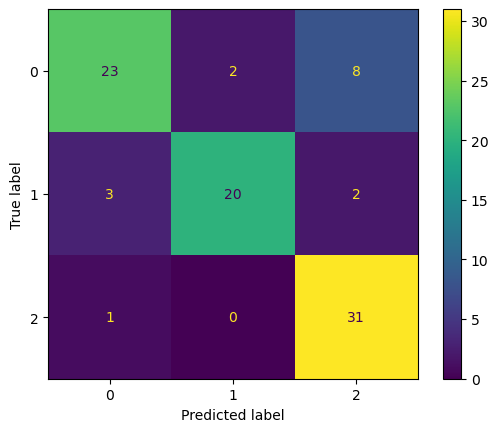

In [101]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=nb.classes_)
disp.plot()
plt.show()

6. On veut étudier comment évoluent les résultats si on applique une étape préalable de réduction de dimension (méthode LDA uniquement). À quelles dimensions peut-on réduire les données ? 

Pour chaque cas possible vous devez :
- calculer les résultats du classifieur bayésien MAP appliqué aux données réduites,
- visualiser les données de test réduites,
- expliquer les résultats obtenus : sont-ils meilleurs ou moins bons que sans réduction de dimension ? Pourquoi ?

In [104]:
#J'ai utilisé le LDA Par défaut donc réduction à une dimension
#On remarque que le matrice de confusion est quasiment exactement la même, il y a une juste un true predicted en plus
#Le jeu de données est trop petit pour avoir des résultats concluant malgré la réduction de dimension


from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis()
X_train_lda = lda.fit_transform(X_train, y_train)
X_test_lda = lda.transform(X_test)


nb = GaussianNB()
nb.fit(X_train_lda, y_train)
y_pred_lda = nb.predict(X_test_lda)
cm = confusion_matrix(y_test, y_pred_lda)

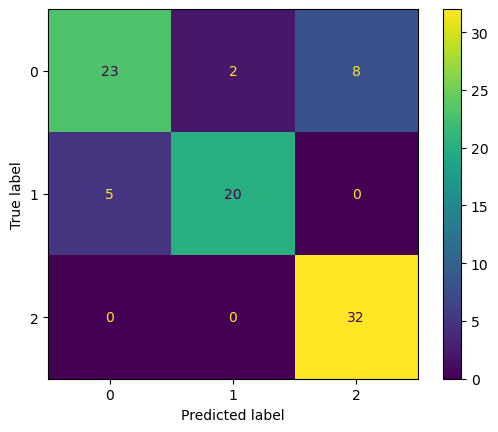

In [105]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=nb.classes_)
disp.plot()
plt.show()